# Practical 09 – K-Means and Hierarchical Clustering Combined

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


In [2]:
raw = load_iris(as_frame=True)
X = raw.data
scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
xy = pca.fit_transform(scaled)


In [3]:
def plot_clusters(labels, title, centers=None):
    plt.figure(figsize=(8, 5))
    plt.scatter(xy[:, 0], xy[:, 1], c=labels, cmap='viridis', s=40)
    if centers is not None:
        pc = pca.transform(centers)
        plt.scatter(pc[:, 0], pc[:, 1], marker='X', s=200, c='red', label='Centroids')
        plt.legend()
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title(title)
    plt.show()


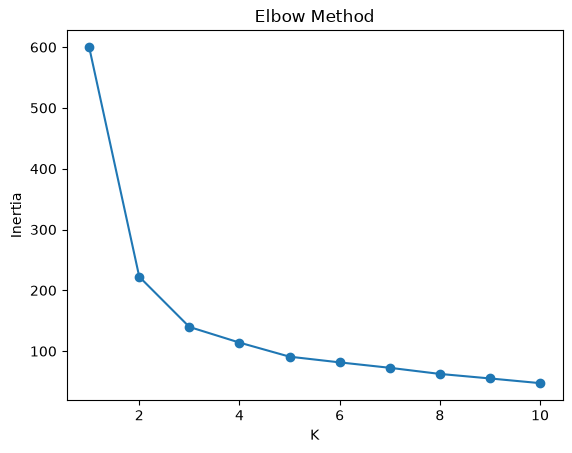

In [7]:
ks = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled).inertia_ for k in ks]
plt.plot(list(ks), inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.show()


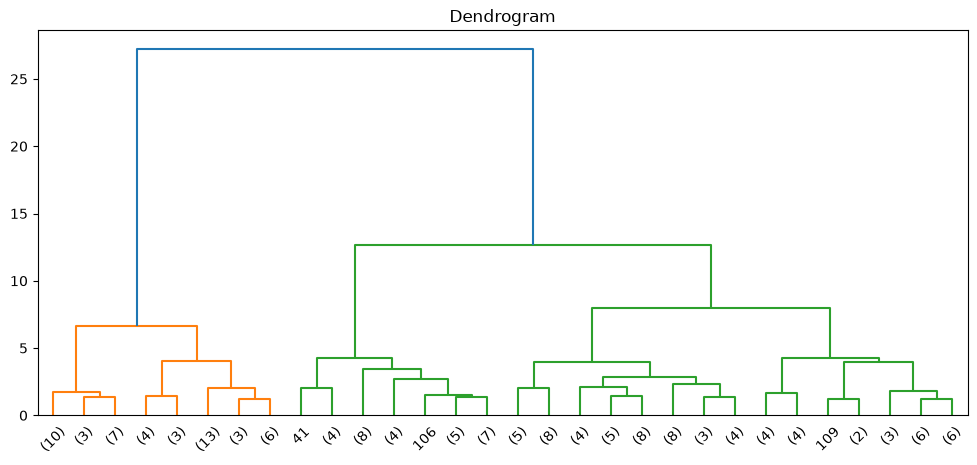

In [5]:
Z = linkage(scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Dendrogram')
plt.show()
km = KMeans(n_clusters=3, n_init=10, random_state=42)
kl = km.fit_predict(scaled)


Silhouette scores: {'K-Means': 0.45994823920518635, 'Hierarchical': 0.4466890410285909}


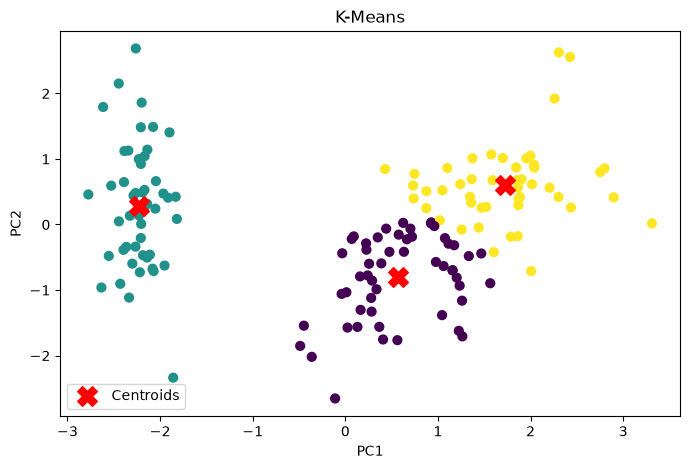

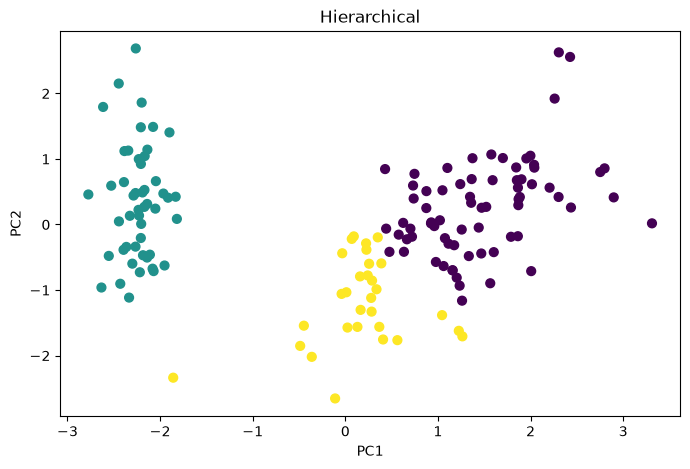

<BarContainer object of 2 artists>

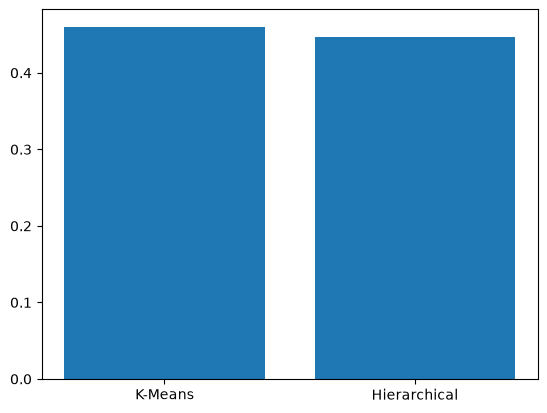

In [6]:
hm = AgglomerativeClustering(n_clusters=3, linkage='ward')
hl = hm.fit_predict(scaled)
results = {'K-Means': silhouette_score(scaled, kl), 'Hierarchical': silhouette_score(scaled, hl)}
print('Silhouette scores:', results)
plot_clusters(kl, 'K-Means', km.cluster_centers_)
plot_clusters(hl, 'Hierarchical')
plt.bar(list(results), list(results.values()))


In [ ]:
plt.ylabel('Silhouette')
plt.title('Comparison')
plt.show()
pd.DataFrame({'KMeans_Cluster': kl, 'Hierarchical_Cluster': hl}).to_csv('clustering_comparison.csv', index=False)
